# E98: Does a neuron version of VPD's r tell reuse from new on the 67M?

*Provisional: fast lane, no independent check. Report with every number: `reports/analyses/2026-11-05_analysis_e98-neuron-r.md`.*

## The answer

Mostly no. We measured the share of a fine-tune's gain carried by the original model's MLP neurons firing differently, their weights unchanged: a neuron stand-in for the decomposition's reading. It told the lowercase task from ciphers, and copying from lookup, but not same-word from random-word maps, nor the elicit map from the cipher. The decomposition's reading separated each of these by about half the gain. Most neuron shares sat near 0.43, where a fine-tune that only adds new output weights also reads.


## What we were trying to test

The user asked for a baseline that does what VPD's readings do, directly on the 67M's MLP neurons and with no decomposition. It was prompted by an essay arguing that neurons are already interpretable. VPD's r is the share of a fine-tune's gain that comes from the original subcomponents being switched on differently, with their weights kept. If neurons can do that job, the decomposition adds nothing to it.

**The neuron share.** A neuron is one of the 12288 GELU outputs across the 67M's four blocks. For each saved fine-tune, the *state*, we run the original model W0 on the task's held-out windows. We hand each MLP the input the state's forward produced, but keep W0's own input and output weights. The readout is the log-odds of the trained answer. With $T_0$ W0's log-odds, $T_1$ the state's, and the gain $G = T_1 - T_0$, the neuron share is the log-odds this patch adds, over $G$. 0 means W0's neurons re-firing carry none of the gain; 1 means they carry all of it.

Three more cells split the rest: the share from the state's new output weights on W0's firing, an interaction, and the share left to attention. With the full-width patch of E52 and E56, which also takes the state's input weights, the four sum to exactly 1.

**The rows.** Seven rows of the method table where VPD's r has readings, 56 states. Each row pairs fine-tunes *built* to reuse something W0 does with fine-tunes *built* to need something new: the same word back against a random word, lowercase against ciphers, an elicit map against a cipher, rank-1 and copy maps against a cipher. These labels are assumptions about how the tasks were built, not causal checks. The seventh row, copy against lookup on an induction task, is the only one with a causal label: switching off W0's copying head removes about half of copy's gain and none of lookup's.

A row separates when the gap between sides exceeds the spread within each side and is at least 0.2. A state counts only when its gain is at least 1 log-odds and, on key-to-value tasks, it has learned its keys.

**The controls**, each ruling out a way the cells could mislead:
- the unchanged model, which must read 0 in every cell;
- the full-width shares E56 published, which must reproduce;
- three fine-tunes of E54's elicit task built so the answer is known. Training only input weights and attention must give the new-weights share 0. Training only the last block's output weights must give it 1. Training every block's output weights and nothing else asks what the neuron share reads when *no* neuron gets a new input weight.


In [1]:
from pathlib import Path

from IPython.display import Image, display

FIG = Path("../experiments/neuron_r/figures")


## What we expected, and why

- **The neuron share would not be a reuse reader.** E52 and E56 found the full-width patch followed training progress, not kind, and reversed on same word against random word. We expected the neuron share to separate on fewer than half of the readable rows where VPD's r separates.
- **Copy gains would sit partly in attention.** The 67M's copy tasks run through a head, as E62 found, so we expected the attention share to be higher on the copy side of every copy row.
- **Lowercase would sit on few neurons, alone.** E63 found about 15 neurons carry half of lowercase's gain. We expected the smallest top set carrying half the neuron share to be at most 32 on lowercase and above 64 everywhere else.

## What we observed

### Do the cells read what three fine-tunes of known make-up put in them?


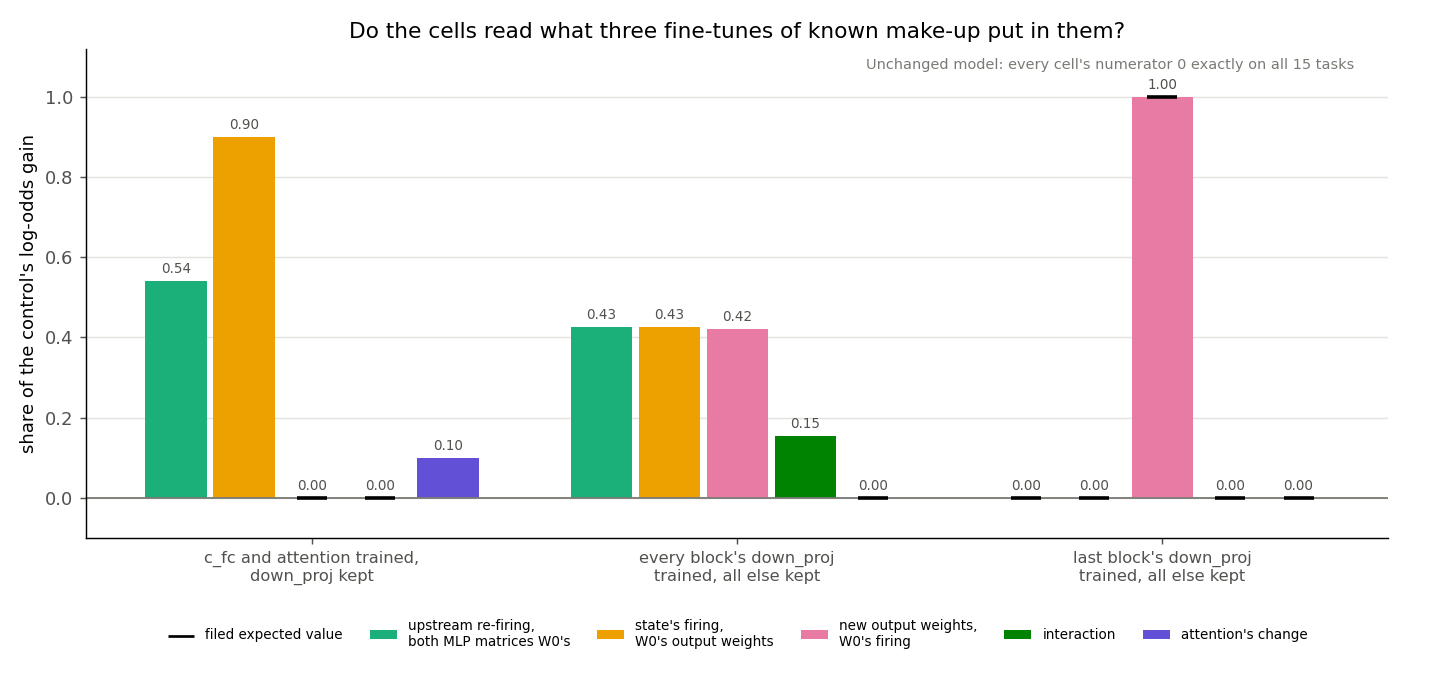

In [2]:
display(Image(FIG / "controls.png", width=900))


**Reading it.** Yes, every control held, and one of them sets a floor for everything that follows. Training only the last block's output weights put the whole gain in the new-weights share and nothing anywhere else. Training only input weights and attention left the new-weights share and interaction at exactly zero. The unchanged model read zero in every cell on all 15 tasks, and E56's shares reproduced within 4e-8.

The middle group is the one to remember. Training every block's output weights gives no neuron a new input weight, yet the neuron share reads **0.43**. A new write direction in block 1 changes what blocks 2 to 4 see, so their neurons re-fire with W0's weights, and the share counts that as reuse. A fine-tune that only adds new output directions therefore already reads 0.43 here. The first job stopped on this control: its filed rule wanted the new-weights share above the full-width share, which the construction did not imply.

### Does the neuron share separate reuse from new where VPD's r does?


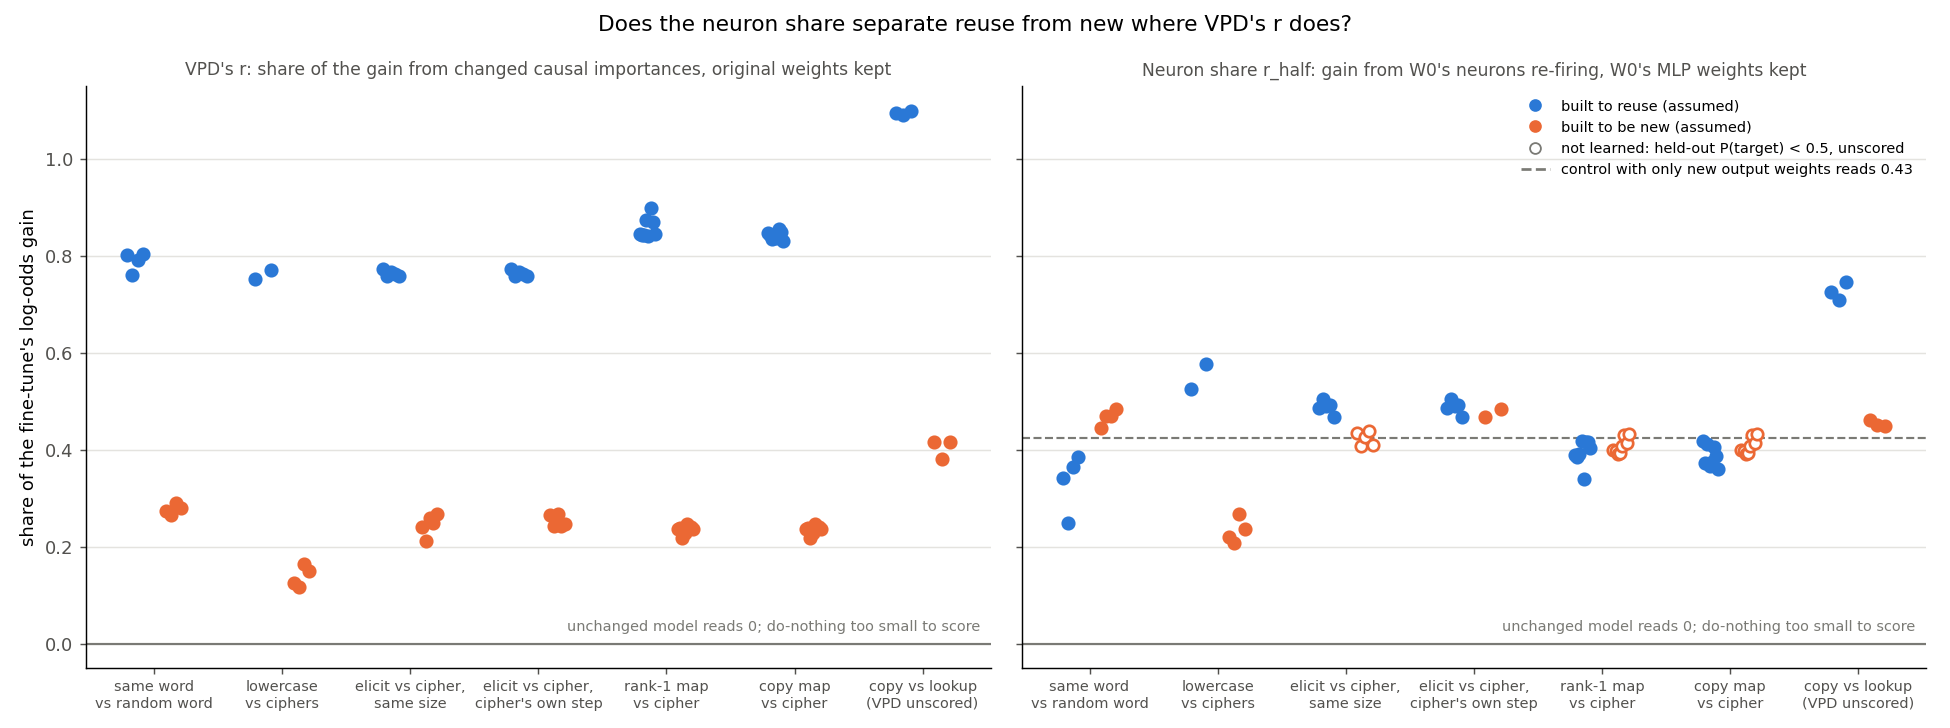

In [3]:
display(Image(FIG / "r_half_vs_vpd_r.png", width=1000))


**Reading it.** Only on lowercase against ciphers among the rows VPD's r separates, plus the causal copy-against-lookup row. On the left, VPD's r puts every blue state above every orange one, by about half the gain, on all six rows it scored. On the right, lowercase reads 0.53 to 0.58 against the ciphers' 0.21 to 0.27. Same word leans the wrong way, below random word, though short of the rule. Elicit and cipher read the same, about 0.48.

On copy against lookup, copy reads about 0.73 and lookup 0.45: a separation in the direction of the causal label. VPD's r was left unscored there because copy read above 1.

Most points on the right sit between 0.35 and 0.50, around the dashed line the output-weights-only control drew. A neuron share inside that band cannot be read as reuse on this model, because new write directions alone produce it. The rank-1 and copy maps against the cipher are unreadable as filed, since the cipher had not learned its keys; read anyway, they show no separation.

### Do copy gains sit in attention?

No: the attention share is at most 0.16 on any state, and no row separates. On same word against random word the copy side is higher, 0.15 against 0.05, but under the rule's 0.2 gap. On copy against lookup it goes the other way. At the answer, most of the copy gain arrives through MLP output; a head whose effect a later MLP relays is credited to the neuron cells, not to attention. The report has the table.

### How few neurons carry half of the re-firing gain?


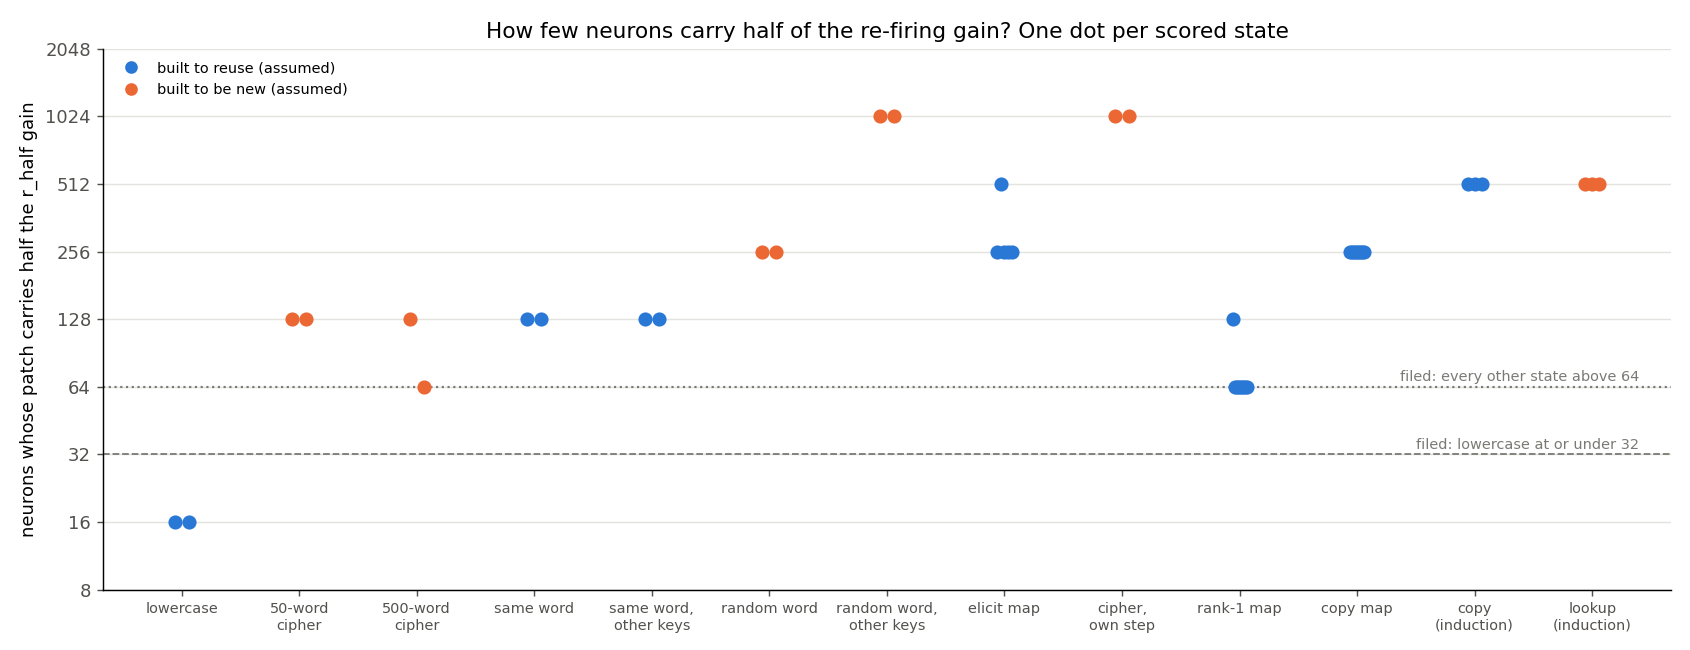

In [4]:
display(Image(FIG / "k_half.png", width=1000))


**Reading it.** Lowercase sits on few neurons, as predicted, but it is not alone. Neurons are ranked by W0's gradient times the change in their activation, and we patch the top few. Both lowercase seeds reach half the neuron share with 16 neurons, matching E63. Seven of the eight rank-1 maps reach it with 64, and so does one 500-word cipher seed, so the prediction failed. Every other state needs 128 to 1024, blue and orange alike.

The rank-1 result is a lead, not a finding. E63's neuron counts did not separate, but they measured how a weight update or activation shift spreads over neurons, not which neurons carry the gain; this count is causal. Against it, the rank-1 maps are low-rank by construction, so a small set may follow from the update's rank; the copy maps, also built to reuse, need 256. The set is also ranked and read on the same windows.


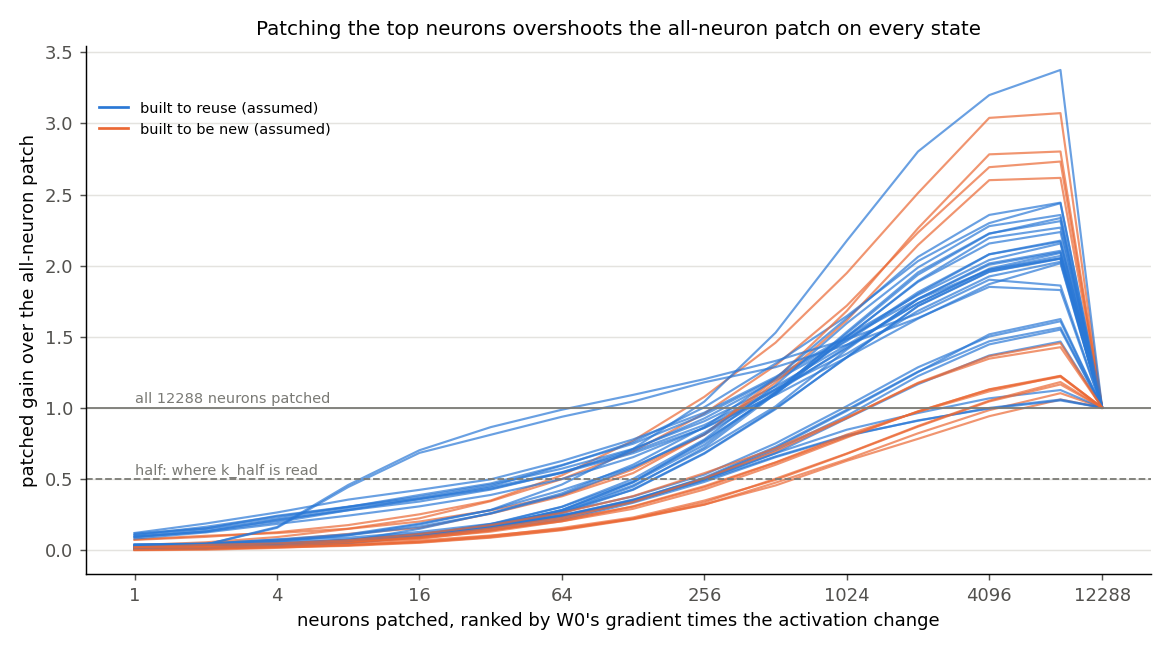

In [5]:
display(Image(FIG / "k_curves.png", width=800))


**Reading it.** A caveat on the counts above: on every state, patching the top-ranked neurons overshoots patching all of them, by up to 3.4 times. The bottom of the ranking holds neurons whose re-firing works against the gain. So "half" is half of a net total much smaller than the gross, and a set that reaches it holds the strongest positive contributors. It is not shown to be needed.

## What the essay's claim would predict here

The essay argues that the MLP neurons of trained language models are already interpretable, mostly one job each, judged by top activations, steering and ablation. It says nothing about fine-tuning. Its natural prediction here is that a fine-tune strengthening something W0 does runs through a few existing neurons re-firing. E98 finds the re-firing share does not follow the construction labels on most rows, chiefly because new output weights in one block show up as re-firing in later blocks. That bears on using neuron firing as a reuse detector on a four-block model, not on whether the neurons are interpretable, which E98 did not test. Lowercase, with 16 neurons, is where the essay's method is worth trying.

## What we learned

A neuron reading without a decomposition does not reproduce VPD's reuse-versus-new separation on the 67M. Its main failure is structural: with stacked MLPs, new write directions in one block make later neurons re-fire, and on this model that floor is about 0.43 of the gain. VPD's r shares the relay blind spot in principle, yet on these rows it separated by about half the gain where the neuron reading did not. So on this model VPD's reading is not a dressed-up neuron patch, though both are judged against assumed labels.

## How compelling is the evidence

- Six of seven rows are labelled by assumption; on the one causal row, the neuron share agreed with the label.
- Three rows were readable under the filed rules, plus the causal row; one model; two to five seeds a side.
- The unchanged model reads exactly zero. The rule's noise floor is each row's spread across seeds.
- Blind to relays: any upstream re-firing, even from new output weights, counts as reuse. That floor was measured on one task and one seed.

## Surprises

- The output-weights-only control reads 0.43 on the neuron share. It was expected to read low.
- Rank-1 maps reach half their re-firing gain with 64 neurons, a quarter of the copy maps' count.
- Top-ranked patches overshoot the all-neuron patch on every state.

## What next

1. **The interpretation step** on lowercase's 16 and rank-1's 64 neurons: top Pile windows in W0, ablation, a written job and a blind test. A coherent job in W0 would make the small count about reuse; none would make it about the update's rank.
2. **Remove the relay**: read the neuron share block by block with later blocks fed W0's MLP input. If the output-weights-only control then reads near zero and same word still fails, the neuron reading fails on kind itself.

## Departures from the literature

- **VPD's r** transplants Γ's causal importances into the original subcomponents. A neuron has no gate apart from its weights, so we transplant the MLP input and keep both MLP matrices W0's.
- **The essay** reads neurons by top activations, steering and ablation; we only measure carrying shares and a carrying set.
- **The ranking** multiplies W0's gradient by the activation's change, where E56's code multiplied by the activation itself.
- **The learned filter** is not applied to lowercase and ciphers, where it would empty the row by construction.

## Scorecard

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| Stage 0 | apparatus | W0 exact; E56 within 1e-5; do-nothing below floor; controls per Amendment 1 | W0 0; E56 within 4e-8; do-nothing 0.16, 0.20; controls held | pass |
| P1 | neuron share not a kind reader | separates on fewer than half of readable rows | separates on e53 only, of e46, e53, e54_own | pass |
| P1r | same, full-width share | as P1 | e46 reversed, e53 separates, e54_own none | pass |
| P2 | copy gains in attention | attention share copy-higher on every readable copy row | none on e46, e54_own, e62 | fail |
| P3 | lowercase alone on few neurons | lowercase ≤ 32, all others > 64 | lowercase 16; rank-1 seeds 1-7 and one broad cipher at 64 | fail |

## Not run

- Four E58 rows whose states were not saved; seeds 2-4 of the cipher at its own step.
- The essay's interpretation step, a relay-free neuron share, heads as units.
- An independent check.
- The output-weights-only control on another task or seed.

**Provenance.** Job 52786, MATS `debug` on one L40, about 4 minutes, $0. Job 52747 stopped at the output-weights-only control. Results: `experiments/neuron_r/results/`. VPD's r: `experiments/method_table/results/table.json`. Figures: `experiments/neuron_r/plot.py`.
